# Deep Learning Assignment: 02
# Group Members:
*   Bisma Maheen (232429)
*   Mudassir Shah (232393)

# Reproducing INP-Former (CVPR 2025)
**Paper:** *Exploring Intrinsic Normal Prototypes within a Single Image for Universal Anomaly Detection*, Luo et al., CVPR 2025.
arXiv: https://arxiv.org/abs/2503.02424 · Official code: https://github.com/luow23/INP-Former (MIT license)
**Dataset:** MVTec AD (https://www.mvtec.com/company/research/datasets/mvtec-ad), license CC BY-NC-SA 4.0 (non-commercial, research use).

### What this notebook does
| Step | What happens | Est. time on free T4 |
|---|---|---|
| 0–3 | Set up GPU, code, libraries, dataset | ~15 min |
| **Exp 1** | Test the authors' trained **multi-class** model on MVTec AD (paper Table 2) | ~5–10 min |
| **Exp 2** | Test the authors' trained **few-shot (4-shot and 1-shot)** models (paper Table 3 / S6) | ~10–20 min |
| Speed test | Train for 3 epochs to measure real speed on your GPU | ~5 min |
| **Exp 3** | **Train it yourself**: single-class model on chosen categories (paper Table 4 / S9) | ~2 h per category (estimate) |
| **Exp 4** (optional) | Train the 1-shot model yourself | ~3 h (estimate) |
| Visuals | Defect heatmaps + paper-vs-ours charts | ~5 min |

Times are estimates. The speed test cell tells you the real numbers on your GPU.

### Before you start
1. **Runtime → Change runtime type → T4 GPU** (or better).
2. Run cells **top to bottom**. If Colab disconnects, re-run **Steps 1–5** (setup; already-finished downloads are skipped where possible), then continue where you stopped. Results and trained models are saved to your **Google Drive**, so they are not lost.
3. You need about **1 GB free on Google Drive** (about **6 GB** if you turn on dataset caching in Step 4).

## Step 1 — Check the GPU and connect Google Drive
Everything important (logs, trained models, figures) is saved to Drive so a disconnect doesn't lose your work.

In [ ]:
!nvidia-smi
import torch, sys
print("Python :", sys.version.split()[0])
print("PyTorch:", torch.__version__, "| CUDA:", torch.version.cuda)
assert torch.cuda.is_available(), "No GPU found! Go to Runtime > Change runtime type > T4 GPU, then re-run."
print("GPU    :", torch.cuda.get_device_name(0))

from google.colab import drive
drive.mount('/content/drive')

Tue Oct 27 21:23:41 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             11W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

## Step 2 — Paths, and download the official code
We pin the exact code version (commit) we used, so anyone can reproduce our run.

In [ ]:
import os
REPO_DIR      = '/content/INP-Former'
DATA_DIR      = '/content/mvtec_anomaly_detection'
DRIVE_DIR     = '/content/drive/MyDrive/INP-Former-Reproduction'   # survives disconnects
OFFICIAL_DIR  = '/content/official_checkpoints'                    # authors' trained models
MY_RESULTS    = f'{DRIVE_DIR}/my_training_results'                 # models YOU train
FIG_DIR       = f'{DRIVE_DIR}/figures'
COMMIT        = '17d265381d9b323a2ef6e05aab0665a85edebe84'         # code version used (May 2026)
for d in [DRIVE_DIR, MY_RESULTS, FIG_DIR, OFFICIAL_DIR]:
    os.makedirs(d, exist_ok=True)

if not os.path.isdir(REPO_DIR):
    !git clone -q https://github.com/luow23/INP-Former.git {REPO_DIR}
%cd {REPO_DIR}
!git checkout -q {COMMIT}
!git log -1 --format="Code commit: %H  (%cd)"

/content/INP-Former
Code commit: 17d265381d9b323a2ef6e05aab0665a85edebe84  (Tue May 26 14:44:50 2026 +0800)


## Step 3 — Install libraries and apply small compatibility fixes
The repo's `requirements.txt` pins very old versions (Python 3.8, numpy 1.19, PyTorch 2.0) that can't be installed on current Colab.
So we use Colab's built-in PyTorch/numpy and install only the extra packages the code needs.

The fixes below **do not change the method**: they only make the code run on newer software and on Colab's 2-CPU machine.
Each change is printed and saved to `changes_made.txt` on Drive (you need this for report part **(e)**).

In [ ]:
!pip install -q timm==0.9.12 adeval==1.1.0 kornia gdown

In [ ]:
import pathlib, datetime
os.chdir(REPO_DIR)
SPEED_UP = True   # removes CUDA_LAUNCH_BLOCKING=1 (a debugging setting that slows training; does not change results)

changes = []
def patch(path, old, new, why):
    p = pathlib.Path(path); s = p.read_text()
    n = s.count(old)
    if n == 0:
        print(f"[already applied / not found] {path}: {why}")
        return
    p.write_text(s.replace(old, new))
    changes.append(f"{path}: {why} ({n} place(s))")
    print(f"[patched] {path}: {why} ({n}x)")

scripts = ['INP_Former_Multi_Class.py', 'INP_Former_Single_Class.py', 'INP_Former_Few_Shot.py']
for s in scripts:
    patch(s, 'num_workers=4', 'num_workers=2', 'num_workers 4 -> 2 (Colab has 2 CPU cores)')
    patch(s, 'nn.utils.clip_grad_norm(', 'nn.utils.clip_grad_norm_(', 'deprecated clip_grad_norm -> clip_grad_norm_ (identical behaviour)')
    if SPEED_UP:
        patch(s, "os.environ['CUDA_LAUNCH_BLOCKING'] = \"1\"", "pass  # CUDA_LAUNCH_BLOCKING removed for speed",
              'removed CUDA_LAUNCH_BLOCKING=1 (speed only)')
patch('utils.py', 'dtype=np.bool)', 'dtype=bool)', 'np.bool -> bool (removed in NumPy >= 1.24)')
patch('models/vit_encoder.py',
      'from torch.hub import HASH_REGEX, download_url_to_file, urlparse',
      'from torch.hub import download_url_to_file\nfrom urllib.parse import urlparse\nimport re\nHASH_REGEX = re.compile(r"-([a-f0-9]*)\\.")',
      'import HASH_REGEX/urlparse directly (robust to newer PyTorch)')
patch('INP_Former_Single_Class.py',
      '    for item in args.item_list:\n',
      "    for item in (os.environ['INP_ITEMS'].split(',') if os.environ.get('INP_ITEMS') else args.item_list):\n",
      'allow choosing categories with env var INP_ITEMS (default = all 15, as in the paper)')

with open(f'{DRIVE_DIR}/changes_made.txt', 'a') as f:
    f.write(f"\n--- {datetime.datetime.now()} ---\n" + "\n".join(changes) + "\n")
print("\nSaved list of changes to", f'{DRIVE_DIR}/changes_made.txt')

[patched] INP_Former_Multi_Class.py: num_workers 4 -> 2 (Colab has 2 CPU cores) (4x)
[patched] INP_Former_Multi_Class.py: deprecated clip_grad_norm -> clip_grad_norm_ (identical behaviour) (1x)
[patched] INP_Former_Multi_Class.py: removed CUDA_LAUNCH_BLOCKING=1 (speed only) (1x)
[patched] INP_Former_Single_Class.py: num_workers 4 -> 2 (Colab has 2 CPU cores) (4x)
[patched] INP_Former_Single_Class.py: deprecated clip_grad_norm -> clip_grad_norm_ (identical behaviour) (1x)
[patched] INP_Former_Single_Class.py: removed CUDA_LAUNCH_BLOCKING=1 (speed only) (1x)
[patched] INP_Former_Few_Shot.py: num_workers 4 -> 2 (Colab has 2 CPU cores) (4x)
[patched] INP_Former_Few_Shot.py: deprecated clip_grad_norm -> clip_grad_norm_ (identical behaviour) (1x)
[patched] INP_Former_Few_Shot.py: removed CUDA_LAUNCH_BLOCKING=1 (speed only) (1x)
[patched] utils.py: np.bool -> bool (removed in NumPy >= 1.24) (1x)
[patched] models/vit_encoder.py: import HASH_REGEX/urlparse directly (robust to newer PyTorch) (1x

## Step 4 — Download the MVTec AD dataset (~4.9 GB)
15 product types (bottle, screw, carpet, …). Training folders contain **only normal** images; test folders contain normal and defective images plus pixel masks of the defects.

By downloading you accept the dataset license (CC BY-NC-SA 4.0, non-commercial).
If the link stops working: open the MVTec download page, accept the license, right-click the **full dataset** link, copy it, and paste it into `MVTEC_URL`.

In [ ]:
MVTEC_URL = "https://www.mydrive.ch/shares/163178/c8212c2166a9e4dfe22dd1bed476a345/download/420938113-1629960298/mvtec_anomaly_detection.tar.xz"
# Download page (if the link above breaks): https://www.mvtec.com/company/research/datasets/mvtec-ad/downloads

CACHE_DATASET_ON_DRIVE = False   # True = keep a copy of the 4.9 GB archive on Drive, so after a disconnect it copies fast instead of re-downloading

import glob, shutil
DRIVE_TAR = f'{DRIVE_DIR}/mvtec_anomaly_detection.tar.xz'
if not os.path.isdir(f'{DATA_DIR}/bottle'):
    %cd /content
    if os.path.exists(DRIVE_TAR):
        print("Copying cached archive from Drive...")
        shutil.copy(DRIVE_TAR, '/content/mvtec.tar.xz')
    else:
        !wget -q --show-progress -O /content/mvtec.tar.xz "{MVTEC_URL}"
        if CACHE_DATASET_ON_DRIVE:
            shutil.copy('/content/mvtec.tar.xz', DRIVE_TAR)
    print("Extracting (a few minutes)...")
    !mkdir -p /content/mvtec_tmp && tar -xf /content/mvtec.tar.xz -C /content/mvtec_tmp
    # find the folder that contains the category folders, whatever the archive layout is
    root = os.path.dirname(glob.glob('/content/mvtec_tmp/**/bottle', recursive=True)[0])
    shutil.move(root, DATA_DIR) if root != '/content/mvtec_tmp' else os.rename('/content/mvtec_tmp', DATA_DIR)
    !rm -f /content/mvtec.tar.xz
    %cd {REPO_DIR}
print("Dataset folder:", DATA_DIR)

/content
/content/mvtec.tar. 100%[===================>]   4.90G  13.1MB/s    in 6m 36s  
Extracting (a few minutes)...
/content/INP-Former
Dataset folder: /content/mvtec_anomaly_detection


In [ ]:
# Document the dataset (report part d): images per category and split
import pandas as pd
CATS = ['carpet','grid','leather','tile','wood','bottle','cable','capsule',
        'hazelnut','metal_nut','pill','screw','toothbrush','transistor','zipper']
rows = []
for c in CATS:
    tr  = len(glob.glob(f'{DATA_DIR}/{c}/train/good/*.png'))
    tg  = len(glob.glob(f'{DATA_DIR}/{c}/test/good/*.png'))
    tb  = len([p for p in glob.glob(f'{DATA_DIR}/{c}/test/*/*.png') if '/good/' not in p])
    dts = sorted(d for d in os.listdir(f'{DATA_DIR}/{c}/test') if d != 'good')
    rows.append([c, tr, tg, tb, ', '.join(dts)])
ds = pd.DataFrame(rows, columns=['category','train (normal)','test normal','test defective','defect types'])
ds.loc['TOTAL'] = ['TOTAL', ds['train (normal)'].sum(), ds['test normal'].sum(), ds['test defective'].sum(), '']
ds.to_csv(f'{DRIVE_DIR}/dataset_summary.csv', index=False)
ds

,category,train (normal),test normal,test defective,defect types
0,carpet,280,28,89,"color, cut, hole, metal_contamination, thread"
1,grid,264,21,57,"bent, broken, glue, metal_contamination, thread"
2,leather,245,32,92,"color, cut, fold, glue, poke"
3,tile,230,33,84,"crack, glue_strip, gray_stroke, oil, rough"
4,wood,247,19,60,"color, combined, hole, liquid, scratch"
5,bottle,209,20,63,"broken_large, broken_small, contamination"
6,cable,224,58,92,"bent_wire, cable_swap, combined, cut_inner_ins..."
7,capsule,219,23,109,"crack, faulty_imprint, poke, scratch, squeeze"
8,hazelnut,391,40,70,"crack, cut, hole, print"
9,metal_nut,220,22,93,"bent, color, flip, scratch"


## Step 5 — Download the authors' trained models
Links come from the official README. They are saved in the exact folder names the scripts expect.
If `gdown` fails (Google Drive sometimes blocks busy files), download the file manually from the README link in your browser and upload it as `model.pth` into the folder printed below.

In [ ]:
import gdown
SUFFIX = '_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6'
OFFICIAL = {
    'INP-Former-Multi-Class' + SUFFIX: '1UBHNSHb-oOLWwImUtqWQI_4nku95ZgOq',
    'INP-Former-Few-Shot-4'  + SUFFIX: '15UtpeFveG2azUQmhogoET2HifEyIKSvX',
    'INP-Former-Few-Shot-1'  + SUFFIX: '1ymAywov3JFFVzwDpcdt9Tj_iFv-mk32c',
}
for folder, file_id in OFFICIAL.items():
    out = f'{OFFICIAL_DIR}/{folder}/model.pth'
    os.makedirs(os.path.dirname(out), exist_ok=True)
    if not os.path.exists(out):
        gdown.download(id=file_id, output=out, quiet=False)
    print(f"{os.path.getsize(out)/1e6:8.1f} MB  {out}")

Downloading...
From (original): https://drive.google.com/uc?id=1UBHNSHb-oOLWwImUtqWQI_4nku95ZgOq
From (redirected): https://drive.google.com/uc?id=1UBHNSHb-oOLWwImUtqWQI_4nku95ZgOq&confirm=t&uuid=c8494e0d-1a7e-43a3-b358-c18a65a67807
To: /content/official_checkpoints/INP-Former-Multi-Class_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth
100%|██████████| 621M/621M [00:21<00:00, 29.2MB/s]


   620.5 MB  /content/official_checkpoints/INP-Former-Multi-Class_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth


Downloading...
From (original): https://drive.google.com/uc?id=15UtpeFveG2azUQmhogoET2HifEyIKSvX
From (redirected): https://drive.google.com/uc?id=15UtpeFveG2azUQmhogoET2HifEyIKSvX&confirm=t&uuid=a7eca681-df2c-4d35-8cf3-e1dac52ff08d
To: /content/official_checkpoints/INP-Former-Few-Shot-4_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth
100%|██████████| 621M/621M [00:19<00:00, 31.2MB/s]


   620.5 MB  /content/official_checkpoints/INP-Former-Few-Shot-4_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth


Downloading...
From (original): https://drive.google.com/uc?id=1ymAywov3JFFVzwDpcdt9Tj_iFv-mk32c
From (redirected): https://drive.google.com/uc?id=1ymAywov3JFFVzwDpcdt9Tj_iFv-mk32c&confirm=t&uuid=a332cce4-f524-4796-a468-311ddb33ed1e
To: /content/official_checkpoints/INP-Former-Few-Shot-1_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth
100%|██████████| 621M/621M [00:17<00:00, 35.3MB/s]

   620.5 MB  /content/official_checkpoints/INP-Former-Few-Shot-1_dataset=MVTec-AD_Encoder=dinov2reg_vit_base_14_Resize=448_Crop=392_INP_num=6/model.pth


## Experiment 1 — Test the authors' multi-class model (paper Table 2)
One model for all 15 categories. The first run also downloads the DINOv2 backbone weights (~350 MB).
Output: per-category scores and a **Mean** line. Paper's mean: **I-AUROC 99.7**, I-AP 99.9, I-F1 99.2, P-AUROC 98.5, P-AP 71.0, P-F1 69.7, AUPRO 94.9.
(The README notes pixel-level AP/F1 may come out slightly lower than the paper because of a later ground-truth fix.)

In [ ]:
%cd {REPO_DIR}
!python INP_Former_Multi_Class.py --dataset MVTec-AD --data_path {DATA_DIR} --save_dir {OFFICIAL_DIR} --phase test 2>&1 | tee {DRIVE_DIR}/exp1_multiclass_official_test.log

/content/INP-Former
100%|██████████| 330M/330M [00:08<00:00, 40.9MB/s]
100%|█████████████████████████████████████████████| 8/8 [00:13<00:00,  1.72s/it]
carpet: I-Auroc:0.9988, I-AP:0.9996, I-F1:0.9944, P-AUROC:0.9935, P-AP:0.6889, P-F1:0.7037, P-AUPRO:0.9789
100%|█████████████████████████████████████████████| 5/5 [00:05<00:00,  1.12s/it]
grid: I-Auroc:0.9992, I-AP:0.9997, I-F1:0.9913, P-AUROC:0.9942, P-AP:0.5208, P-F1:0.5544, P-AUPRO:0.9775
100%|█████████████████████████████████████████████| 8/8 [00:09<00:00,  1.22s/it]
leather: I-Auroc:1.0000, I-AP:1.0000, I-F1:1.0000, P-AUROC:0.9942, P-AP:0.5259, P-F1:0.5463, P-AUPRO:0.9813
100%|█████████████████████████████████████████████| 8/8 [00:09<00:00,  1.19s/it]
tile: I-Auroc:1.0000, I-AP:1.0000, I-F1:1.0000, P-AUROC:0.9768, P-AP:0.7405, P-F1:0.7304, P-AUPRO:0.8836
100%|█████████████████████████████████████████████| 5/5 [00:06<00:00,  1.31s/it]
wood: I-Auroc:0.9991, I-AP:0.9997, I-F1:0.9917, P-AUROC:0.9754, P-AP:0.7223, P-F1:0.6740, P-AUPRO:0

## Experiment 2 — Test the authors' few-shot models (paper Table 3 and Table S6)
Few-shot = the model only saw **4** (or **1**) normal photos per product type.
Paper means on MVTec AD — 4-shot: **I-AUROC 97.6**; 1-shot: **I-AUROC 96.6**.

In [ ]:
%cd {REPO_DIR}
for shot in [4, 1]:
    !python INP_Former_Few_Shot.py --dataset MVTec-AD --data_path {DATA_DIR} --save_dir {OFFICIAL_DIR} --shot {shot} --phase test 2>&1 | tee {DRIVE_DIR}/exp2_fewshot{shot}_official_test.log

/content/INP-Former
[('/content/mvtec_anomaly_detection/carpet/train/good/068.png', 0), ('/content/mvtec_anomaly_detection/carpet/train/good/032.png', 0), ('/content/mvtec_anomaly_detection/carpet/train/good/130.png', 0), ('/content/mvtec_anomaly_detection/carpet/train/good/060.png', 0)]
[('/content/mvtec_anomaly_detection/grid/train/good/253.png', 1), ('/content/mvtec_anomaly_detection/grid/train/good/230.png', 1), ('/content/mvtec_anomaly_detection/grid/train/good/241.png', 1), ('/content/mvtec_anomaly_detection/grid/train/good/194.png', 1)]
[('/content/mvtec_anomaly_detection/leather/train/good/201.png', 2), ('/content/mvtec_anomaly_detection/leather/train/good/053.png', 2), ('/content/mvtec_anomaly_detection/leather/train/good/024.png', 2), ('/content/mvtec_anomaly_detection/leather/train/good/124.png', 2)]
[('/content/mvtec_anomaly_detection/tile/train/good/007.png', 3), ('/content/mvtec_anomaly_detection/tile/train/good/228.png', 3), ('/content/mvtec_anomaly_detection/tile/train/

## Speed test — how long will training take on YOUR GPU?
Trains on `bottle` for 3 epochs (paper uses 200) into a throw-away folder, then estimates the full time.
This also confirms that training works before you start a long run.

In [ ]:
import time
%cd {REPO_DIR}
t0 = time.time()
!INP_ITEMS=bottle python INP_Former_Single_Class.py --dataset MVTec-AD --data_path {DATA_DIR} --save_dir /content/speedtest --total_epochs 3 --phase train 2>&1 | tail -n 5
elapsed = time.time() - t0
per_epoch = elapsed / 3          # slight over-estimate: includes model loading + testing
print(f"\n3 epochs took {elapsed/60:.1f} min -> about {per_epoch:.0f} s per epoch for 'bottle' (209 training images)")
print(f"Estimated full 200-epoch training for 'bottle': ~{per_epoch*200/3600:.1f} hours")
print("Categories with more training images (e.g. carpet 280, screw 320, hazelnut 391) take proportionally longer.")

/content/INP-Former
epoch [3/3], loss:0.3887
100%|█████████████████████████████████████████████| 6/6 [00:09<00:00,  1.55s/it]
bottle: I-Auroc:0.9897, I-AP:0.9973, I-F1:0.9920, P-AUROC:0.9527, P-AP:0.7497, P-F1:0.7216, P-AUPRO:0.9153
[['bottle', np.float64(0.9896825396825396), np.float64(0.997284878863826), np.float64(0.9919999500032024), 0.9526559965920578, 0.749723595718158, np.float64(0.7216171773228924), np.float64(0.9152748369235169)]]
Mean: I-Auroc:0.9897, I-AP:0.9973, I-F1:0.9920, P-AUROC:0.9527, P-AP:0.7497, P-F1:0.7216, P-AUPRO:0.9153

3 epochs took 2.3 min -> about 46 s per epoch for 'bottle' (209 training images)
Estimated full 200-epoch training for 'bottle': ~2.5 hours
Categories with more training images (e.g. carpet 280, screw 320, hazelnut 391) take proportionally longer.


## Experiment 3 — Train the model yourself (single-class, paper Table 4 / Table S9)
One model per product type, trained from scratch with the **paper's exact settings** (200 epochs, batch 16, 448→392 images, 6 prototypes).
Start with `bottle`. When it finishes, add more categories (one per Colab session is safest), e.g. `screw`, `cable`, `carpet`, `transistor`.
Already-trained categories are skipped automatically, and models + logs are saved on Drive.

Compare each category with the per-category numbers in the paper's appendix (Table S9) — enter them in the results cell below.

In [ ]:
CATEGORIES = ['bottle']      # add more later, e.g. ['bottle', 'screw', 'cable', 'carpet', 'transistor']

SINGLE_NAME = 'INP-Former-Single-Class' + SUFFIX
%cd {REPO_DIR}
for cat in CATEGORIES:
    done = os.path.exists(f'{MY_RESULTS}/{SINGLE_NAME}/{cat}/model.pth')
    if done:
        print(f"[skip] {cat} already trained"); continue
    print(f"=== Training {cat} ===")
    !INP_ITEMS={cat} python INP_Former_Single_Class.py --dataset MVTec-AD --data_path {DATA_DIR} --save_dir {MY_RESULTS} --phase train 2>&1 | tee -a {DRIVE_DIR}/exp3_singleclass_train.log

/content/INP-Former
=== Training bottle ===
train image number:209
100%|███████████████████████████████████████████| 13/13 [00:35<00:00,  2.77s/it]
epoch [1/200], loss:0.7794
100%|███████████████████████████████████████████| 13/13 [00:33<00:00,  2.60s/it]
epoch [2/200], loss:0.4505
100%|███████████████████████████████████████████| 13/13 [00:33<00:00,  2.56s/it]
epoch [3/200], loss:0.3887
100%|███████████████████████████████████████████| 13/13 [00:34<00:00,  2.63s/it]
epoch [4/200], loss:0.3660
100%|███████████████████████████████████████████| 13/13 [00:33<00:00,  2.58s/it]
epoch [5/200], loss:0.3692
100%|███████████████████████████████████████████| 13/13 [00:33<00:00,  2.56s/it]
epoch [6/200], loss:0.3309
100%|███████████████████████████████████████████| 13/13 [00:33<00:00,  2.57s/it]
epoch [7/200], loss:0.3356
100%|███████████████████████████████████████████| 13/13 [00:32<00:00,  2.52s/it]
epoch [8/200], loss:0.3416
100%|███████████████████████████████████████████| 13/13 [00:32<00:00,

## Experiment 4 (optional) — Train the 1-shot model yourself
Trains on just **1 normal photo per category** (each expanded into 22 augmented copies by the authors' code), for all 15 categories, 200 epochs.
Estimated ~3 h on a T4. Compare with the paper (I-AUROC 96.6) **and** with the authors' 1-shot model from Experiment 2.

In [ ]:
RUN_EXP4 = True   # set to True to run
if RUN_EXP4:
    %cd {REPO_DIR}
    !python INP_Former_Few_Shot.py --dataset MVTec-AD --data_path {DATA_DIR} --save_dir {MY_RESULTS} --shot 1 --phase train 2>&1 | tee {DRIVE_DIR}/exp4_fewshot1_train.log

## Visualization — see what the model sees
For a few test images: the photo, the true defect mask, and the model's anomaly heatmap (red = "looks abnormal").
All heatmaps use the same color scale, so a normal ("good") image should look mostly blue.

In [ ]:
%%writefile /content/INP-Former/inp_vis.py
import os, glob, random
import numpy as np, torch, torch.nn as nn, matplotlib.pyplot as plt
from functools import partial
from PIL import Image
from dataset import get_data_transforms
from models import vit_encoder
from models.uad import INP_Former
from models.vision_transformer import Mlp, Aggregation_Block, Prototype_Block
from utils import cal_anomaly_maps, get_gaussian_kernel

def build_model(encoder_name='dinov2reg_vit_base_14', INP_num=6, device='cuda'):
    # identical construction to INP_Former_Multi_Class.py
    target_layers = [2, 3, 4, 5, 6, 7, 8, 9]
    fuse = [[0, 1, 2, 3], [4, 5, 6, 7]]
    encoder = vit_encoder.load(encoder_name)
    embed_dim, num_heads = 768, 12
    if 'small' in encoder_name: embed_dim, num_heads = 384, 6
    if 'large' in encoder_name:
        embed_dim, num_heads = 1024, 16
        target_layers = [4, 6, 8, 10, 12, 14, 16, 18]
    norm = partial(nn.LayerNorm, eps=1e-8)
    bottleneck = nn.ModuleList([Mlp(embed_dim, embed_dim * 4, embed_dim, drop=0.)])
    inp = nn.ParameterList([nn.Parameter(torch.randn(INP_num, embed_dim))])
    extractor = nn.ModuleList([Aggregation_Block(dim=embed_dim, num_heads=num_heads, mlp_ratio=4., qkv_bias=True, norm_layer=norm)])
    decoder = nn.ModuleList([Prototype_Block(dim=embed_dim, num_heads=num_heads, mlp_ratio=4., qkv_bias=True, norm_layer=norm) for _ in range(8)])
    model = INP_Former(encoder=encoder, bottleneck=bottleneck, aggregation=extractor, decoder=decoder,
                       target_layers=target_layers, remove_class_token=True, fuse_layer_encoder=fuse,
                       fuse_layer_decoder=fuse, prototype_token=inp)
    return model.to(device).eval()

def show_examples(ckpt_path, data_dir, categories, n_defect=2, input_size=448, crop_size=392, save_path=None, seed=0):
    device = 'cuda'
    model = build_model(device=device)
    model.load_state_dict(torch.load(ckpt_path, map_location=device), strict=True)
    tf, _ = get_data_transforms(input_size, crop_size)
    kernel = get_gaussian_kernel(kernel_size=5, sigma=4).to(device)
    rng = random.Random(seed)
    picks = []
    for cat in categories:
        bad = sorted(p for p in glob.glob(f'{data_dir}/{cat}/test/*/*.png') if '/good/' not in p)
        good = sorted(glob.glob(f'{data_dir}/{cat}/test/good/*.png'))
        picks += [(cat, p) for p in rng.sample(bad, min(n_defect, len(bad)))] + [(cat, rng.choice(good))]
    o = (input_size - crop_size) // 2
    results = []
    for cat, p in picks:
        img = Image.open(p).convert('RGB')
        x = tf(img).unsqueeze(0).to(device)
        with torch.no_grad():
            en, de = model(x)[:2]
            amap, _ = cal_anomaly_maps(en, de, x.shape[-1])
            amap = kernel(amap)
            flat = amap.flatten(1)
            score = torch.sort(flat, dim=1, descending=True)[0][:, :int(flat.shape[1] * 0.01)].mean().item()  # mean of top-1% pixels, like the evaluation code
        disp = np.array(img.resize((input_size, input_size)))[o:o + crop_size, o:o + crop_size]
        gt_path = p.replace('/test/', '/ground_truth/').replace('.png', '_mask.png')
        gt = (np.array(Image.open(gt_path).convert('L').resize((input_size, input_size)))[o:o + crop_size, o:o + crop_size]
              if os.path.exists(gt_path) else np.zeros(disp.shape[:2]))
        results.append((cat, p.split('/')[-2], disp, gt, amap[0, 0].cpu().numpy(), score))
    vmax = max(r[4].max() for r in results)
    fig, axes = plt.subplots(len(results), 3, figsize=(9, 3 * len(results)))
    for i, (cat, kind, disp, gt, amap, score) in enumerate(results):
        axes[i, 0].imshow(disp); axes[i, 0].set_title(f'{cat} / {kind}')
        axes[i, 1].imshow(gt, cmap='gray'); axes[i, 1].set_title('True defect mask')
        axes[i, 2].imshow(disp); axes[i, 2].imshow(amap, cmap='jet', alpha=0.5, vmin=0, vmax=vmax)
        axes[i, 2].set_title(f'Model heatmap (score {score:.3f})')
        for a in axes[i]: a.axis('off')
    plt.tight_layout()
    if save_path: plt.savefig(save_path, dpi=110, bbox_inches='tight')
    plt.show()

Writing /content/INP-Former/inp_vis.py


/content/INP-Former


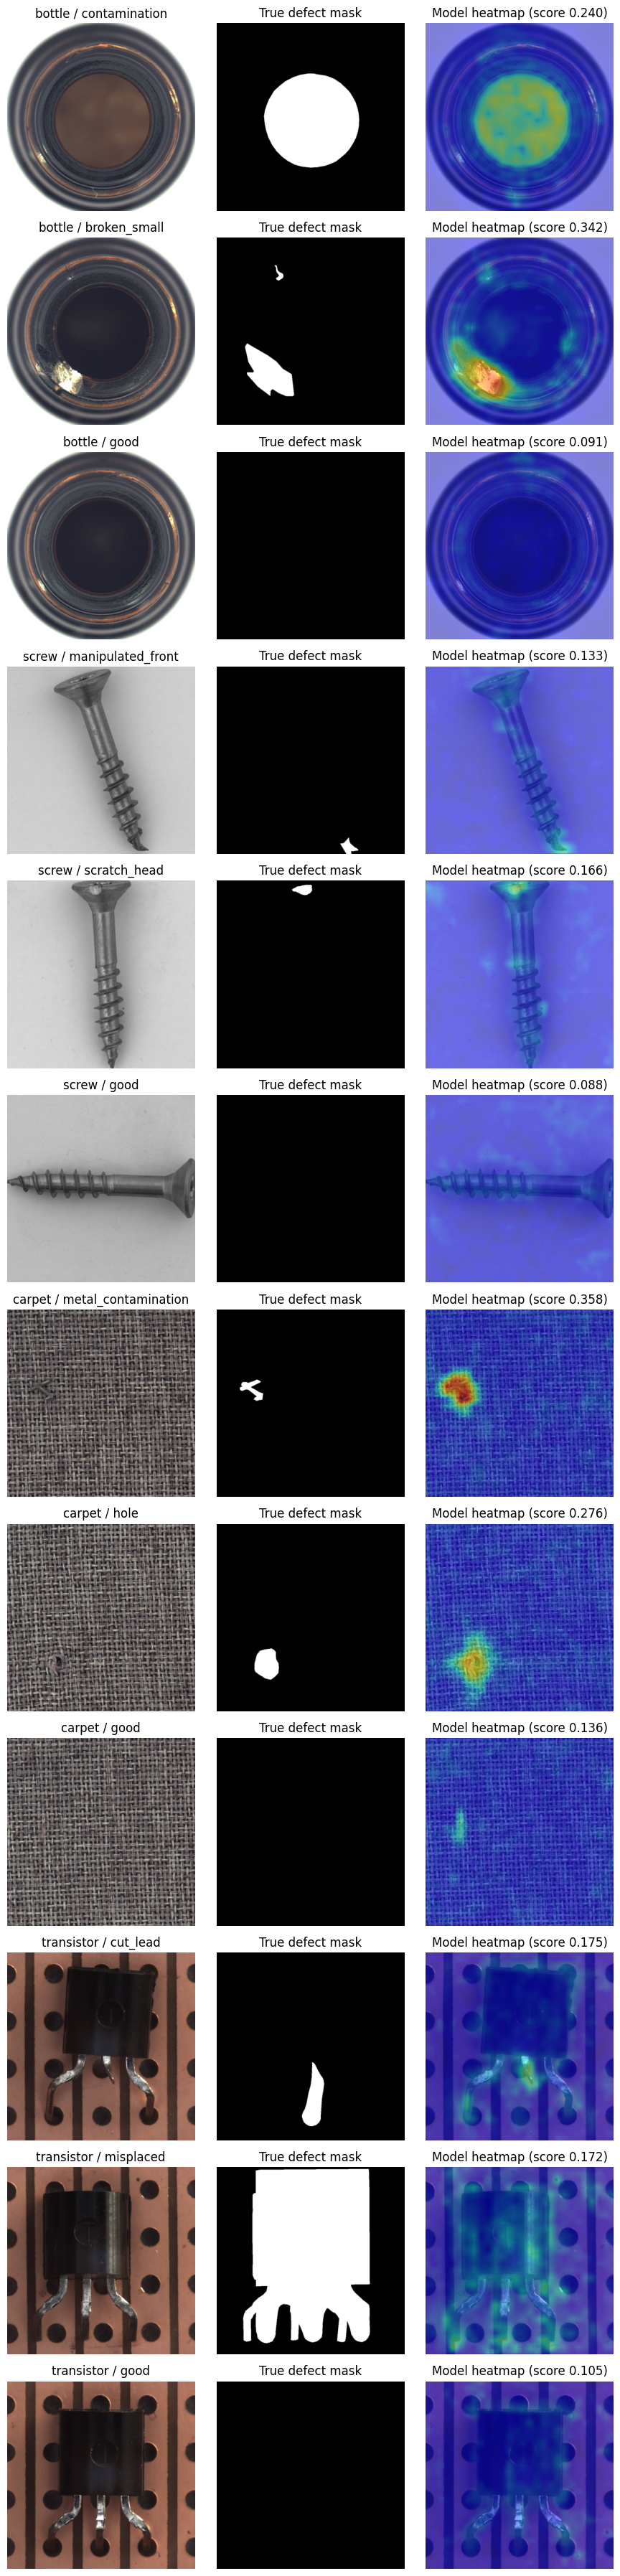

In [ ]:
%cd {REPO_DIR}
import importlib, inp_vis; importlib.reload(inp_vis)
inp_vis.show_examples(
    ckpt_path=f"{OFFICIAL_DIR}/INP-Former-Multi-Class{SUFFIX}/model.pth",
    data_dir=DATA_DIR,
    categories=['bottle', 'screw', 'carpet', 'transistor'],
    save_path=f'{FIG_DIR}/heatmaps_official_multiclass.png')

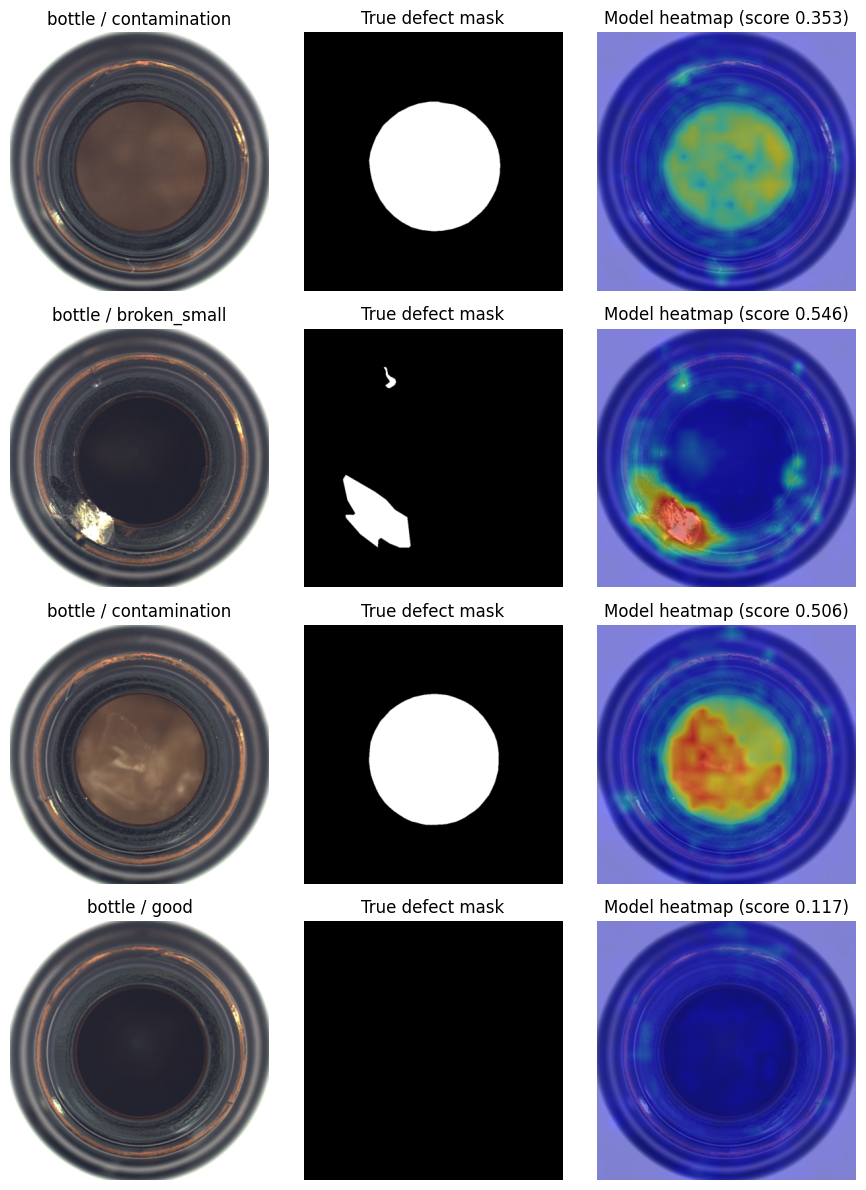

In [ ]:
# Heatmaps from YOUR trained single-class model (run after Experiment 3)
cat = 'bottle'
my_ckpt = f"{MY_RESULTS}/INP-Former-Single-Class{SUFFIX}/{cat}/model.pth"
if os.path.exists(my_ckpt):
    inp_vis.show_examples(ckpt_path=my_ckpt, data_dir=DATA_DIR, categories=[cat], n_defect=3,
                          save_path=f'{FIG_DIR}/heatmaps_my_singleclass_{cat}.png')
else:
    print("Train it first in Experiment 3:", my_ckpt)

## Results — paper vs ours (report parts **f** and **g**)
Reads the logs saved on Drive, builds the comparison table, computes **Difference = Ours − Paper**, and draws charts.
Main metric = **I-AUROC** (image-level: "is this product defective?").

For Experiment 3, fill in `PAPER_SINGLE` with the per-category numbers from the paper's appendix (Table S9).

In [ ]:
import re, numpy as np, pandas as pd, matplotlib.pyplot as plt
METRICS = ['I-AUROC', 'I-AP', 'I-F1', 'P-AUROC', 'P-AP', 'P-F1', 'AUPRO']
LINE = re.compile(r'(\w+): I-Auroc:([\d.]+), I-AP:([\d.]+), I-F1:([\d.]+), P-AUROC:([\d.]+), P-AP:([\d.]+), P-F1:([\d.]+), P-AUPRO:([\d.]+)')

def read_log(path):
    # returns {name: [7 metrics in %]}; later lines overwrite earlier ones
    out = {}
    if not os.path.exists(path): return out
    for m in LINE.finditer(open(path).read()):
        vals = [float(v) for v in m.groups()[1:]]
        out[m.group(1)] = [v * 100 if v <= 1.0 else v for v in vals]
    return out

# Paper numbers (MVTec AD means) from the paper: Table 2, Table 3, Table S6
PAPER = {
    'Exp1 Multi-class (official model)': [99.7, 99.9, 99.2, 98.5, 71.0, 69.7, 94.9],
    'Exp2 4-shot (official model)':      [97.6, 98.6, 97.0, 97.0, 65.9, 65.6, 92.9],
    'Exp2 1-shot (official model)':      [96.6, 98.2, 96.4, 97.0, 64.2, 64.0, 92.6],
    'Exp4 1-shot (trained by us)':       [96.6, 98.2, 96.4, 97.0, 64.2, 64.0, 92.6],
}
LOGS = {
    'Exp1 Multi-class (official model)': f'{DRIVE_DIR}/exp1_multiclass_official_test.log',
    'Exp2 4-shot (official model)':      f'{DRIVE_DIR}/exp2_fewshot4_official_test.log',
    'Exp2 1-shot (official model)':      f'{DRIVE_DIR}/exp2_fewshot1_official_test.log',
    'Exp4 1-shot (trained by us)':       f'{DRIVE_DIR}/exp4_fewshot1_train.log',
}
rows = []
for exp, path in LOGS.items():
    ours = read_log(path).get('Mean')
    if ours is None:
        print(f"(no results yet for {exp})"); continue
    for metric, p, o in zip(METRICS, PAPER[exp], ours):
        rows.append([exp, metric, p, round(o, 2), round(o - p, 2)])
summary = pd.DataFrame(rows, columns=['Experiment', 'Metric', 'Paper', 'Ours', 'Difference (Ours - Paper)'])
summary.to_csv(f'{DRIVE_DIR}/results_summary.csv', index=False)
summary

(no results yet for Exp4 1-shot (trained by us))


,Experiment,Metric,Paper,Ours,Difference (Ours - Paper)
0,Exp1 Multi-class (official model),I-AUROC,99.7,99.67,-0.03
1,Exp1 Multi-class (official model),I-AP,99.9,99.88,-0.02
2,Exp1 Multi-class (official model),I-F1,99.2,99.20,0.00
3,Exp1 Multi-class (official model),P-AUROC,98.5,98.45,-0.05
4,Exp1 Multi-class (official model),P-AP,71.0,67.98,-3.02
5,Exp1 Multi-class (official model),P-F1,69.7,67.73,-1.97
6,Exp1 Multi-class (official model),AUPRO,94.9,94.95,0.05
7,Exp2 4-shot (official model),I-AUROC,97.6,97.59,-0.01
8,Exp2 4-shot (official model),I-AP,98.6,98.64,0.04
9,Exp2 4-shot (official model),I-F1,97.0,96.96,-0.04


In [ ]:
# Experiment 3: per-category single-class results vs paper (fill in from paper Table S9)
PAPER_SINGLE = {   # category: paper I-AUROC (%) — copy from the paper's appendix
    'bottle': None, 'screw': None, 'cable': None, 'carpet': None, 'transistor': None,
}
mine = read_log(f'{DRIVE_DIR}/exp3_singleclass_train.log')
rows = [[c, PAPER_SINGLE.get(c), round(v[0], 2), round(v[0] - PAPER_SINGLE[c], 2) if PAPER_SINGLE.get(c) else None]
        for c, v in mine.items() if c != 'Mean']
single = pd.DataFrame(rows, columns=['Category', 'Paper I-AUROC', 'Our I-AUROC', 'Difference'])
single.to_csv(f'{DRIVE_DIR}/results_singleclass.csv', index=False)
single

,Category,Paper I-AUROC,Our I-AUROC,Difference
0,bottle,None,100.0,None


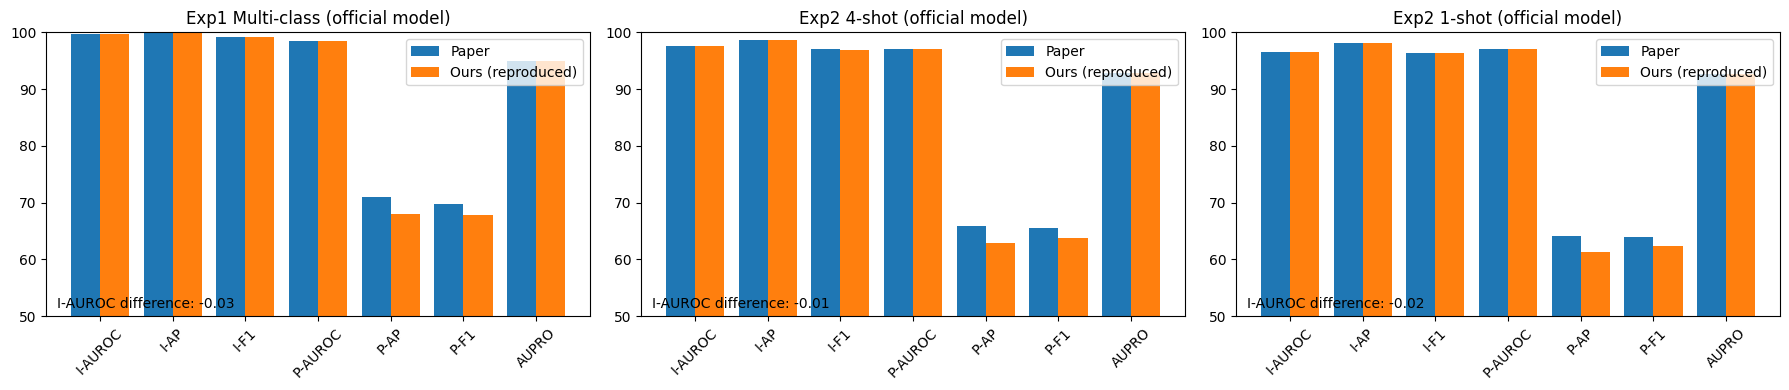

In [ ]:
# Charts: paper vs ours for each experiment
if len(summary):
    exps = summary['Experiment'].unique()
    fig, axes = plt.subplots(1, len(exps), figsize=(6 * len(exps), 4), squeeze=False)
    for ax, exp in zip(axes[0], exps):
        d = summary[summary['Experiment'] == exp]
        x = np.arange(len(d))
        ax.bar(x - 0.2, d['Paper'], 0.4, label='Paper')
        ax.bar(x + 0.2, d['Ours'], 0.4, label='Ours (reproduced)')
        ax.set_xticks(x); ax.set_xticklabels(d['Metric'], rotation=45)
        ax.set_ylim(min(50, d[['Paper', 'Ours']].values.min() - 5), 100)
        ax.set_title(exp); ax.legend()
        main = d[d['Metric'] == 'I-AUROC'].iloc[0]
        ax.text(0.02, 0.03, f"I-AUROC difference: {main['Difference (Ours - Paper)']:+.2f}", transform=ax.transAxes)
    plt.tight_layout(); plt.savefig(f'{FIG_DIR}/paper_vs_ours.png', dpi=110, bbox_inches='tight'); plt.show()
if len(single):
    s = single.dropna()
    if len(s):
        x = np.arange(len(s))
        plt.figure(figsize=(7, 4))
        plt.bar(x - 0.2, s['Paper I-AUROC'], 0.4, label='Paper'); plt.bar(x + 0.2, s['Our I-AUROC'], 0.4, label='Ours (trained)')
        plt.xticks(x, s['Category']); plt.ylim(80, 100.5); plt.legend(); plt.title('Exp 3: single-class I-AUROC per category')
        plt.savefig(f'{FIG_DIR}/singleclass_paper_vs_ours.png', dpi=110, bbox_inches='tight'); plt.show()

## Record the environment (report part **e** and execution evidence)
Saves GPU, Python, library versions, code commit and the list of changes to Drive. Take screenshots of the Experiment outputs too.

In [ ]:
import platform, subprocess
info = [
    f"Date: {datetime.datetime.now()}",
    f"GPU: {torch.cuda.get_device_name(0)}",
    f"Python: {platform.python_version()}",
    f"PyTorch: {torch.__version__}  CUDA: {torch.version.cuda}",
    "Code commit: " + subprocess.getoutput(f'git -C {REPO_DIR} rev-parse HEAD'),
    "Settings: encoder=dinov2reg_vit_base_14, input 448 -> crop 392, INP_num=6, batch 16, 200 epochs, StableAdamW lr 1e-3 (paper defaults)",
]
open(f'{DRIVE_DIR}/environment.txt', 'w').write("\n".join(info) + "\n")
!pip freeze > {DRIVE_DIR}/pip_freeze.txt
!nvidia-smi > {DRIVE_DIR}/nvidia_smi.txt
print("\n".join(info))
print("\nSaved: environment.txt, pip_freeze.txt, nvidia_smi.txt, changes_made.txt, logs, CSVs and figures in", DRIVE_DIR)

Date: 2026-10-27 23:40:02.628165
GPU: Tesla T4
Python: 3.13.16
PyTorch: 2.11.0+cu130  CUDA: 13.0
Code commit: 17d265381d9b323a2ef6e05aab0665a85edebe84
Settings: encoder=dinov2reg_vit_base_14, input 448 -> crop 392, INP_num=6, batch 16, 200 epochs, StableAdamW lr 1e-3 (paper defaults)

Saved: environment.txt, pip_freeze.txt, nvidia_smi.txt, changes_made.txt, logs, CSVs and figures in /content/drive/MyDrive/INP-Former-Reproduction
